Libraries imported successfully!
Dataset loaded successfully!

DATASET OVERVIEW
Number of Rows    : 614
Number of Columns : 13

FIRST 5 ROWS
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History

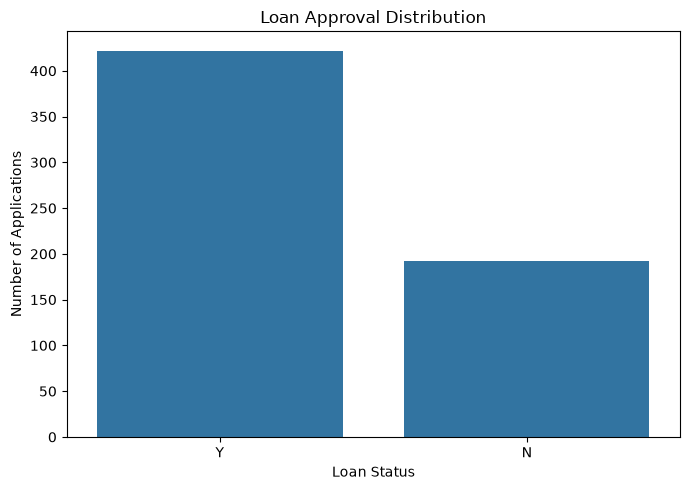

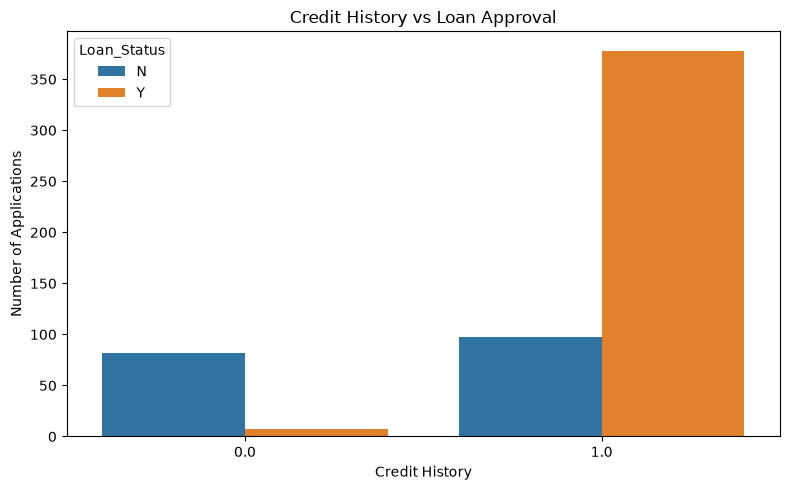

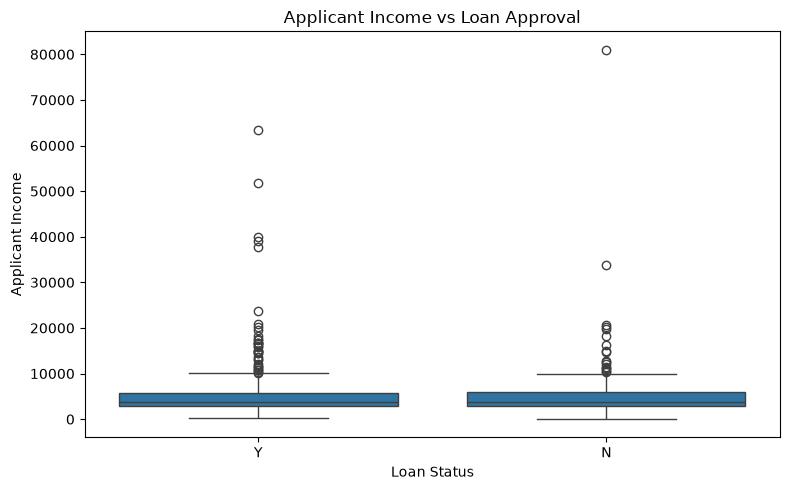

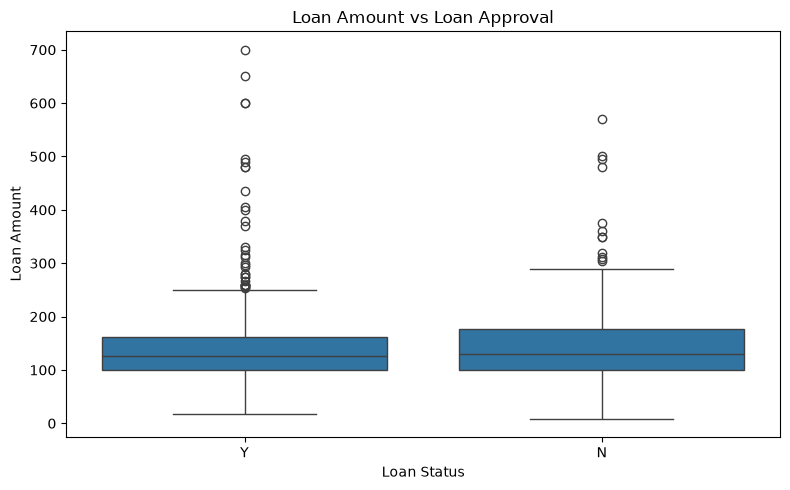

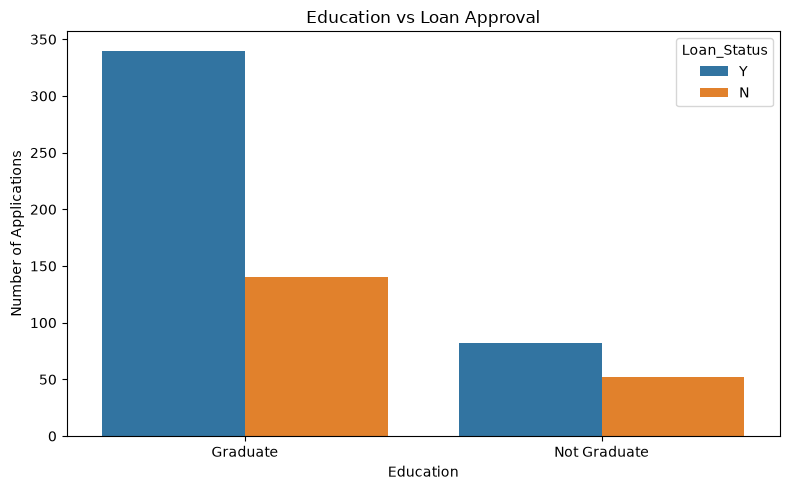

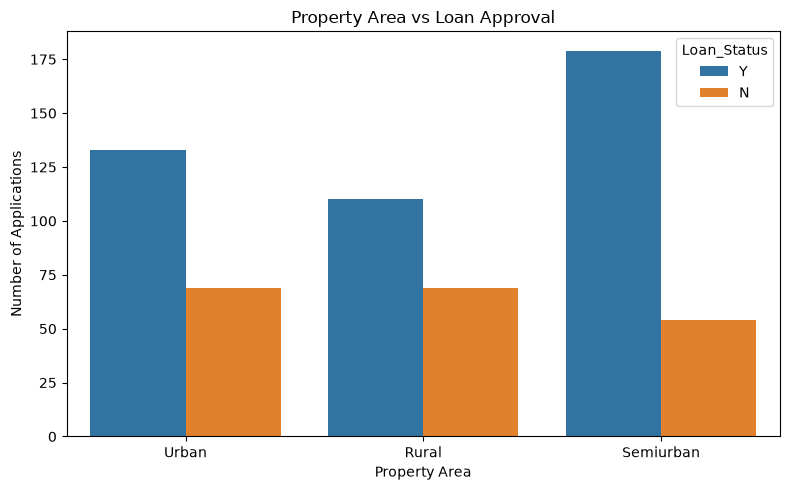

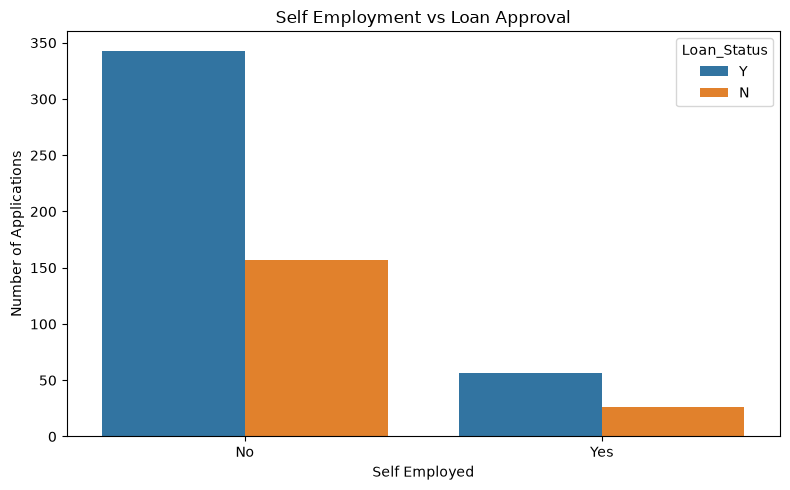

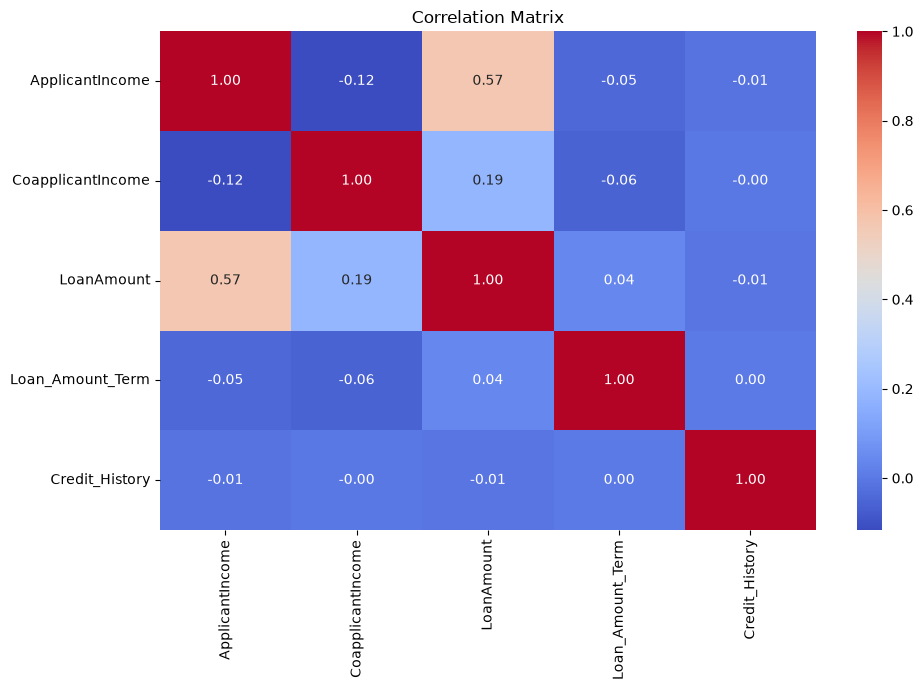


DATA QUALITY REPORT
               Column Data_Type  Missing_Values  Missing_Percentage  \
0             Loan_ID       str               0                0.00   
1              Gender       str              13                2.12   
2             Married       str               3                0.49   
3          Dependents       str              15                2.44   
4           Education       str               0                0.00   
5       Self_Employed       str              32                5.21   
6     ApplicantIncome     int64               0                0.00   
7   CoapplicantIncome   float64               0                0.00   
8          LoanAmount   float64              22                3.58   
9    Loan_Amount_Term   float64              14                2.28   
10     Credit_History   float64              50                8.14   
11      Property_Area       str               0                0.00   
12        Loan_Status       str               0         

In [3]:
# ============================================================
# LOAN APPROVAL & RISK ANALYTICS
# File: 01_data_understanding.ipynb
# Purpose: Load and understand the raw loan dataset
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")


# ============================================================
# 2. LOAD DATASET
# ============================================================

DATA_PATH = "../data/loan_train.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")


# ============================================================
# 3. BASIC INFORMATION
# ============================================================

print("\n" + "=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Number of Rows    : {df.shape[0]}")
print(f"Number of Columns : {df.shape[1]}")


# ============================================================
# 4. FIRST FIVE ROWS
# ============================================================

print("\n" + "=" * 60)
print("FIRST 5 ROWS")
print("=" * 60)

print(df.head())


# ============================================================
# 5. LAST FIVE ROWS
# ============================================================

print("\n" + "=" * 60)
print("LAST 5 ROWS")
print("=" * 60)

print(df.tail())


# ============================================================
# 6. COLUMN NAMES
# ============================================================

print("\n" + "=" * 60)
print("COLUMN NAMES")
print("=" * 60)

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")


# ============================================================
# 7. DATA TYPES AND INFORMATION
# ============================================================

print("\n" + "=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

df.info()


# ============================================================
# 8. STATISTICAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("STATISTICAL SUMMARY")
print("=" * 60)

print(df.describe())


# ============================================================
# 9. MISSING VALUES
# ============================================================

print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)

missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

print(missing_values)


# ============================================================
# 10. DUPLICATE RECORDS
# ============================================================

print("\n" + "=" * 60)
print("DUPLICATE RECORDS")
print("=" * 60)

duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")


# ============================================================
# 11. UNIQUE VALUES
# ============================================================

print("\n" + "=" * 60)
print("UNIQUE VALUES")
print("=" * 60)

unique_values = pd.DataFrame({
    "Column": df.columns,
    "Unique_Values": [df[col].nunique() for col in df.columns]
})

print(unique_values)


# ============================================================
# 12. TARGET VARIABLE ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("LOAN STATUS DISTRIBUTION")
print("=" * 60)

loan_status_count = df["Loan_Status"].value_counts()

print(loan_status_count)

print("\nLoan Status Percentage:")

loan_status_percentage = (
    df["Loan_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(loan_status_percentage)


# ============================================================
# 13. TARGET VARIABLE VISUALIZATION
# ============================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Loan_Status"
)

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.show()


# ============================================================
# 14. CREDIT HISTORY VS LOAN STATUS
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Credit_History",
    hue="Loan_Status"
)

plt.title("Credit History vs Loan Approval")
plt.xlabel("Credit History")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.show()


# ============================================================
# 15. APPLICANT INCOME VS LOAN STATUS
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Loan_Status",
    y="ApplicantIncome"
)

plt.title("Applicant Income vs Loan Approval")
plt.xlabel("Loan Status")
plt.ylabel("Applicant Income")

plt.tight_layout()
plt.show()


# ============================================================
# 16. LOAN AMOUNT VS LOAN STATUS
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Loan_Status",
    y="LoanAmount"
)

plt.title("Loan Amount vs Loan Approval")
plt.xlabel("Loan Status")
plt.ylabel("Loan Amount")

plt.tight_layout()
plt.show()


# ============================================================
# 17. EDUCATION VS LOAN STATUS
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Education",
    hue="Loan_Status"
)

plt.title("Education vs Loan Approval")
plt.xlabel("Education")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.show()


# ============================================================
# 18. PROPERTY AREA VS LOAN STATUS
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Property_Area",
    hue="Loan_Status"
)

plt.title("Property Area vs Loan Approval")
plt.xlabel("Property Area")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.show()


# ============================================================
# 19. SELF EMPLOYED VS LOAN STATUS
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Self_Employed",
    hue="Loan_Status"
)

plt.title("Self Employment vs Loan Approval")
plt.xlabel("Self Employed")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.show()


# ============================================================
# 20. CORRELATION ANALYSIS
# ============================================================

numeric_columns = df.select_dtypes(
    include=np.number
).columns

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()


# ============================================================
# 21. DATA QUALITY REPORT
# ============================================================

data_quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Values": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().sum().values / len(df) * 100
    ).round(2),
    "Unique_Values": df.nunique().values
})

print("\n" + "=" * 60)
print("DATA QUALITY REPORT")
print("=" * 60)

print(data_quality_report)


# ============================================================
# 22. SAVE DATA QUALITY REPORT
# ============================================================

data_quality_report.to_csv(
    "../data/data_quality_report.csv",
    index=False
)

print("\nData quality report saved successfully!")


# ============================================================
# 23. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("DATA UNDERSTANDING COMPLETED")
print("=" * 60)

print(f"Rows              : {df.shape[0]}")
print(f"Columns           : {df.shape[1]}")
print(f"Duplicate Rows    : {df.duplicated().sum()}")
print(f"Missing Values    : {df.isnull().sum().sum()}")
print(f"Target Variable   : Loan_Status")

print("\nNext Stage:")
print("Data Cleaning & Feature Engineering")